In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

import sklearn
import scipy
import joblib
import fastapi
import streamlit

print("Credit Card Fraud Detection")
print("Environment setup successful!")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("SciPy:", scipy.__version__)
print("Streamlit:", streamlit.__version__)

Credit Card Fraud Detection
Environment setup successful!
Pandas: 3.0.6
NumPy: 2.5.4
Scikit-learn: 1.9.1
SciPy: 1.18.1
Streamlit: 1.65.0


# LOADING DATA

In [2]:

from pathlib import Path
import pandas as pd

# Locate the project root and dataset folder
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data"

# Display CSV files available in the data folder
csv_files = list(DATA_DIR.glob("*.csv"))

print("Project root:", PROJECT_ROOT)
print("Data folder:", DATA_DIR)
print("CSV files found:", [file.name for file in csv_files])

Project root: c:\Users\DELL\Downloads\Credit Card Fraud Detection\Notebooks
Data folder: c:\Users\DELL\Downloads\Credit Card Fraud Detection\Notebooks\data
CSV files found: []


In [1]:

from pathlib import Path

print("Current working directory:")
print(Path.cwd())

Current working directory:
c:\Users\DELL\Downloads\Credit Card Fraud Detection\Notebooks


In [5]:

from pathlib import Path
import pandas as pd
import numpy as np

# Step 1: Identify the project folder
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "Notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Step 2: Locate the data folder
DATA_DIR = PROJECT_ROOT / "data"

# Step 3: Look for CSV files inside the data folder
csv_files = list(DATA_DIR.glob("*.csv"))

print("CSV files found:", [file.name for file in csv_files])

CSV files found: ['creditcard.csv']


In [6]:

if len(csv_files) != 1:
    raise ValueError(
        f"Expected exactly one CSV file, but found: "
        f"{[file.name for file in csv_files]}"
    )

DATA_PATH = csv_files[0]

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("File:", DATA_PATH.name)
print("Number of rows and columns:", df.shape)

display(df.head())

Dataset loaded successfully!
File: creditcard.csv
Number of rows and columns: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


# DATA CLEANING

In [7]:
display(df.head(10))

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0
5,2.0,-0.425966,0.960523,1.141109,-0.168252,0.420987,-0.029728,0.476201,0.260314,-0.568671,...,-0.208254,-0.559825,-0.026398,-0.371427,-0.232794,0.105915,0.253844,0.081080,3.67,0
6,4.0,1.229658,0.141004,0.045371,1.202613,0.191881,0.272708,-0.005159,0.081213,0.464960,...,-0.167716,-0.270710,-0.154104,-0.780055,0.750137,-0.257237,0.034507,0.005168,4.99,0
7,7.0,-0.644269,1.417964,1.074380,-0.492199,0.948934,0.428118,1.120631,-3.807864,0.615375,...,1.943465,-1.015455,0.057504,-0.649709,-0.415267,-0.051634,-1.206921,-1.085339,40.80,0
8,7.0,-0.894286,0.286157,-0.113192,-0.271526,2.669599,3.721818,0.370145,0.851084,-0.392048,...,-0.073425,-0.268092,-0.204233,1.011592,0.373205,-0.384157,0.011747,0.142404,93.20,0
9,9.0,-0.338262,1.119593,1.044367,-0.222187,0.499361,-0.246761,0.651583,0.069539,-0.736727,...,-0.246914,-0.633753,-0.120794,-0.385050,-0.069733,0.094199,0.246219,0.083076,3.68,0


In [9]:
display(df.tail())

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0
284806,172792.0,-0.533413,-0.189733,0.703337,-0.506271,-0.012546,-0.649617,1.577006,-0.414650,0.486180,...,0.261057,0.643078,0.376777,0.008797,-0.473649,-0.818267,-0.002415,0.013649,217.00,0


In [10]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

Dataset shape: (284807, 31)

Column names:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

Data types:
Time      float64
V1        float64
V2        float64
V3        float64
V4        float64
V5        float64
V6        float64
V7        float64
V8        float64
V9        float64
V10       float64
V11       float64
V12       float64
V13       float64
V14       float64
V15       float64
V16       float64
V17       float64
V18       float64
V19       float64
V20       float64
V21       float64
V22       float64
V23       float64
V24       float64
V25       float64
V26       float64
V27       float64
V28       float64
Amount    float64
Class       int64
dtype: object


In [11]:
print("Missing values per column:")
display(df.isnull().sum())

print("Total missing values:", df.isnull().sum().sum())

print("Number of duplicate rows:", df.duplicated().sum())

Missing values per column:


Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

Total missing values: 0
Number of duplicate rows: 1081


In [13]:
df.drop_duplicates(inplace=True)
print("Number of duplicate rows after dropping duplicates:", df.duplicated().sum()) 

Number of duplicate rows after dropping duplicates: 0


In [14]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Time,283726.0,94811.077600,47481.047891,0.000000,54204.750000,84692.500000,139298.000000,172792.000000
V1,283726.0,0.005917,1.948026,-56.407510,-0.915951,0.020384,1.316068,2.454930
V2,283726.0,-0.004135,1.646703,-72.715728,-0.600321,0.063949,0.800283,22.057729
V3,283726.0,0.001613,1.508682,-48.325589,-0.889682,0.179963,1.026960,9.382558
V4,283726.0,-0.002966,1.414184,-5.683171,-0.850134,-0.022248,0.739647,16.875344
V5,283726.0,0.001828,1.377008,-113.743307,-0.689830,-0.053468,0.612218,34.801666
V6,283726.0,-0.001139,1.331931,-26.160506,-0.769031,-0.275168,0.396792,73.301626
V7,283726.0,0.001801,1.227664,-43.557242,-0.552509,0.040859,0.570474,120.589494
V8,283726.0,-0.000854,1.179054,-73.216718,-0.208828,0.021898,0.325704,20.007208
V9,283726.0,-0.001596,1.095492,-13.434066,-0.644221,-0.052596,0.595977,15.594995


# EXPLORATORY DATA ANALYSIS

In [15]:
print(df["Class"].value_counts())

print("\nPercentages:")
print(df["Class"].value_counts(normalize=True) * 100)

Class
0    283253
1       473
Name: count, dtype: int64

Percentages:
Class
0    99.83329
1     0.16671
Name: proportion, dtype: float64


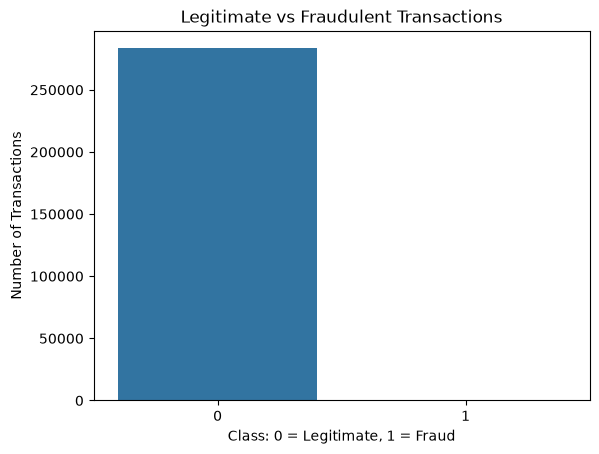

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="Class")
plt.title("Legitimate vs Fraudulent Transactions")
plt.xlabel("Class: 0 = Legitimate, 1 = Fraud")
plt.ylabel("Number of Transactions")
plt.show()

# EXAMINE TRANSACTION AMOUNT

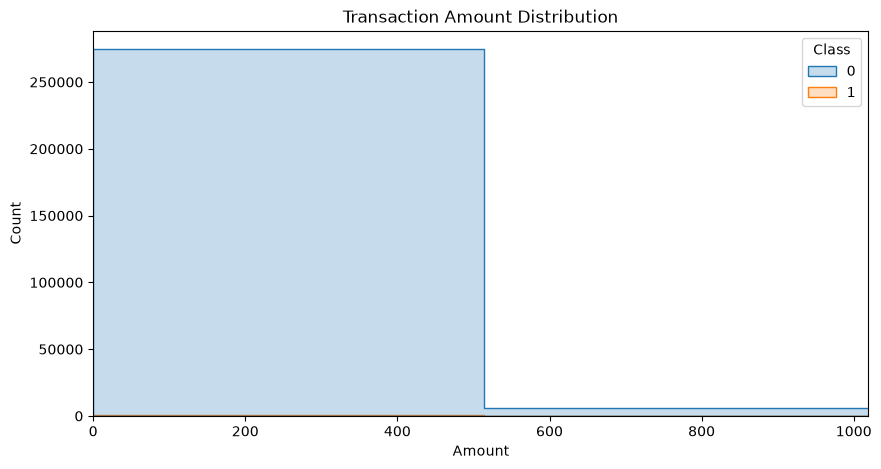

In [17]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Amount",
    hue="Class",
    bins=50,
    element="step"
)

plt.title("Transaction Amount Distribution")
plt.xlim(0, df["Amount"].quantile(0.99))
plt.show()

# EXAMINING TRANSACTION TIME

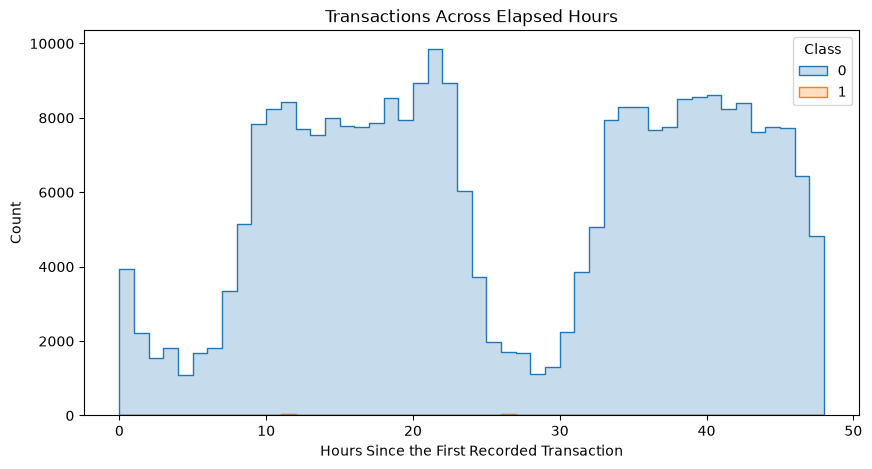

In [19]:
df["ElapsedHour"] = df["Time"] / 3600

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="ElapsedHour",
    hue="Class",
    bins=48,
    element="step"
)

plt.title("Transactions Across Elapsed Hours")
plt.xlabel("Hours Since the First Recorded Transaction")
plt.show()

# EXAMINING SELECTED FEATURES

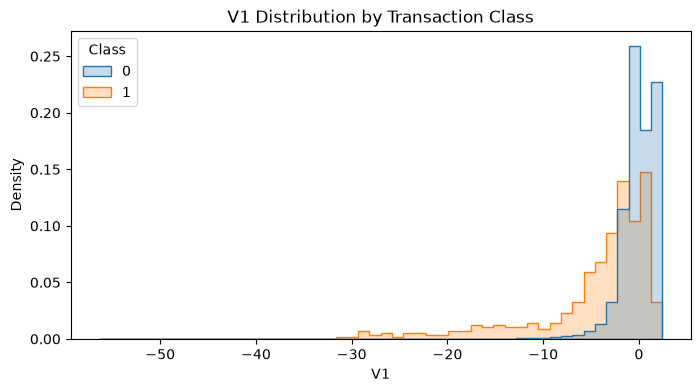

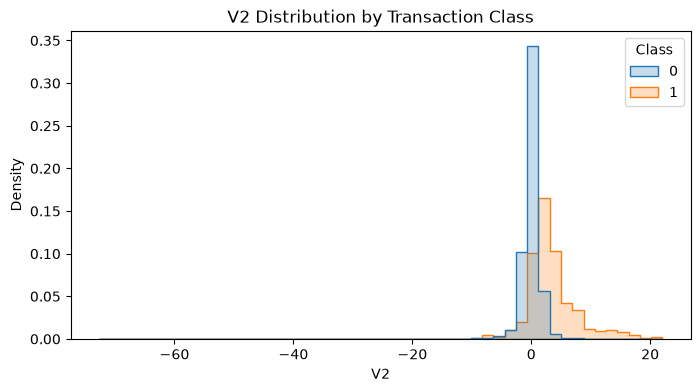

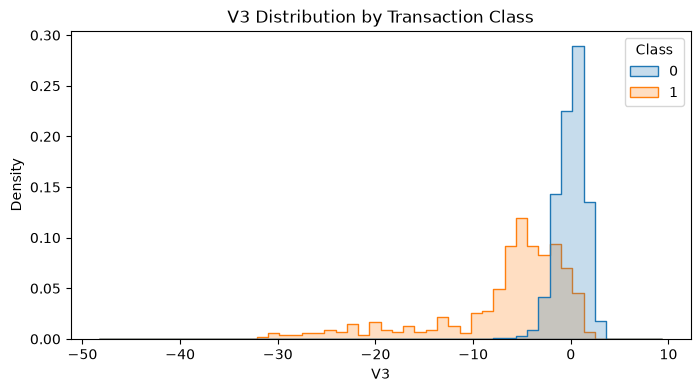

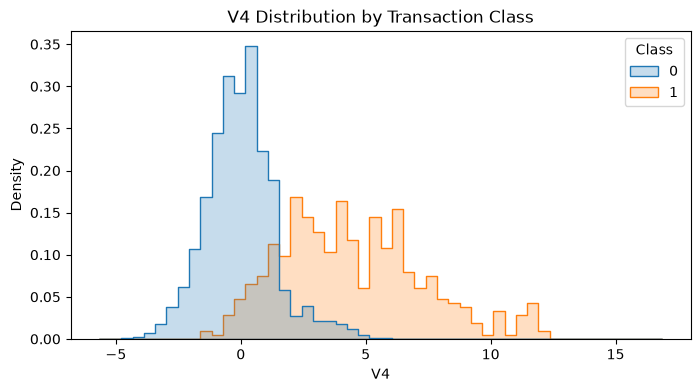

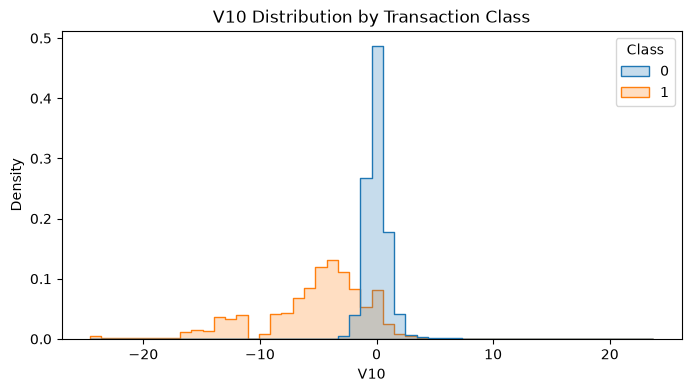

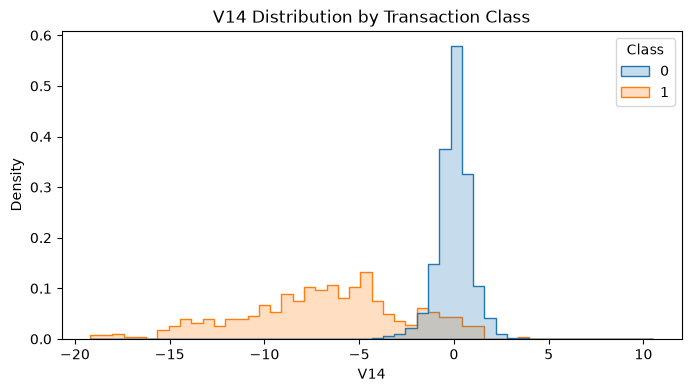

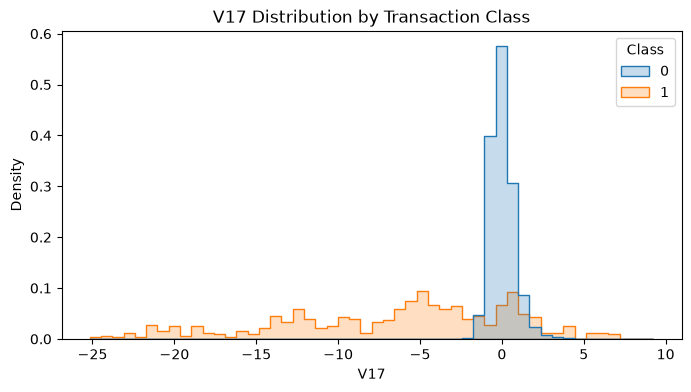

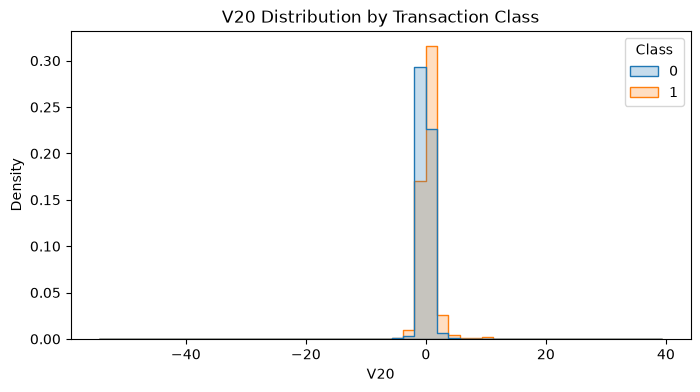

In [20]:
selected_features = ["V1", "V2", "V3", "V4", "V10", "V14", "V17", "V20"]

for feature in selected_features:
    plt.figure(figsize=(8, 4))

    sns.histplot(
        data=df,
        x=feature,
        hue="Class",
        bins=50,
        element="step",
        stat="density",
        common_norm=False
    )

    plt.title(f"{feature} Distribution by Transaction Class")
    plt.show()

# VISUALIZING THE DATA USING PCA

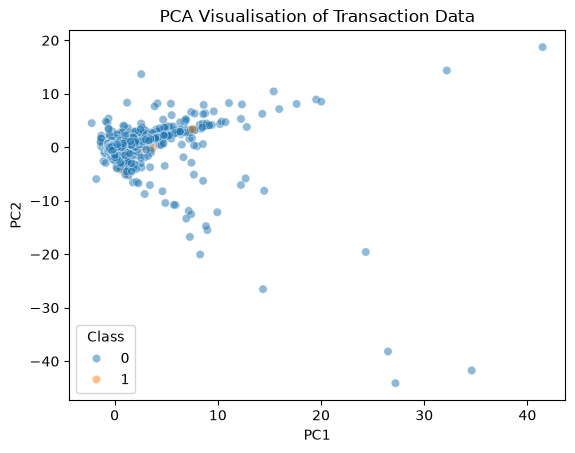

Variance explained: 0.1167107308090333


In [21]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

pca_features = [f"V{i}" for i in range(1, 29)] + ["Amount"]

sample = df.sample(
    n=min(10000, len(df)),
    random_state=42
)

X_sample = sample[pca_features]

pca_scaler = StandardScaler()
X_sample_scaled = pca_scaler.fit_transform(X_sample)

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_sample_scaled)

pca_df = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"]
)

pca_df["Class"] = sample["Class"].to_numpy()

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Class",
    alpha=0.5
)

plt.title("PCA Visualisation of Transaction Data")
plt.show()

print(
    "Variance explained:",
    pca.explained_variance_ratio_.sum()
)

# PREPARING THE DATA FOR MACHINE LEARNING

In [ ]:
# Separate the features from the target
from sklearn.model_selection import train_test_split

FEATURES = [
    column for column in df.columns
    if column not in ["Class", "ElapsedHour", "ApproxHourOfDay"]
]

X = df[FEATURES].copy()
y = df["Class"].astype(int).copy()

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("Features:", FEATURES)

Features shape: (283726, 30)
Target shape: (283726,)
Features: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount']


# SPLITTING THE DATA INTO TRAINING, VALIDATION, AND TEST

In [23]:
from sklearn.model_selection import train_test_split

FEATURES = [
    column for column in df.columns
    if column not in ["Class", "ElapsedHour", "ApproxHourOfDay"]
]

X = df[FEATURES].copy()
y = df["Class"].astype(int).copy()

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("Features:", FEATURES)

Features shape: (283726, 30)
Target shape: (283726,)
Features: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount']


# SCALING THE FEATURES

In [25]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))
print("Test rows:", len(X_test))

Training rows: 170235
Validation rows: 56745
Test rows: 56746


In [26]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_normal = X_train.loc[y_train == 0]

scaler.fit(X_train_normal)

X_train_normal_scaled = scaler.transform(X_train_normal)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Normal training data:", X_train_normal_scaled.shape)
print("Validation data:", X_val_scaled.shape)
print("Test data:", X_test_scaled.shape)

Normal training data: (169951, 30)
Validation data: (56745, 30)
Test data: (56746, 30)


# TRAIN AN ANOMALY DETECTION MODEL

In [28]:
from sklearn.ensemble import IsolationForest

isolation_forest = IsolationForest(
    n_estimators=200,
    contamination="auto",
    random_state=42,
    n_jobs=-1
)

isolation_forest.fit(X_train_normal_scaled)

print("Isolation Forest training completed.")

Isolation Forest training completed.


In [29]:
# Generate anomaly scores for the validation and test sets
val_scores = -isolation_forest.score_samples(X_val_scaled)

print("First 10 anomaly scores:")
print(val_scores[:10])

First 10 anomaly scores:
[0.44267267 0.40161679 0.44467413 0.41296153 0.49794396 0.39229986
 0.38924514 0.46422343 0.42018808 0.38897382]


In [30]:
# COMPARE WITH LOCAL OUTLIER FACTOR (LOF)
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import average_precision_score

rng = np.random.default_rng(42)

normal_count = min(10000, len(X_train_normal_scaled))
train_indices = rng.choice(
    len(X_train_normal_scaled),
    size=normal_count,
    replace=False
)

lof = LocalOutlierFactor(
    n_neighbors=35,
    novelty=True,
    contamination="auto",
    n_jobs=-1
)

lof.fit(X_train_normal_scaled[train_indices])

val_count = min(5000, len(X_val_scaled))
val_indices = rng.choice(
    len(X_val_scaled),
    size=val_count,
    replace=False
)

lof_scores = -lof.score_samples(X_val_scaled[val_indices])

lof_ap = average_precision_score(
    y_val.to_numpy()[val_indices],
    lof_scores
)

print("LOF validation Average Precision:", round(lof_ap, 5))

LOF validation Average Precision: 0.65787


# EVALUATE THE MODEL AND SELECT A THRESHOLD

Validation Average Precision: 0.08148


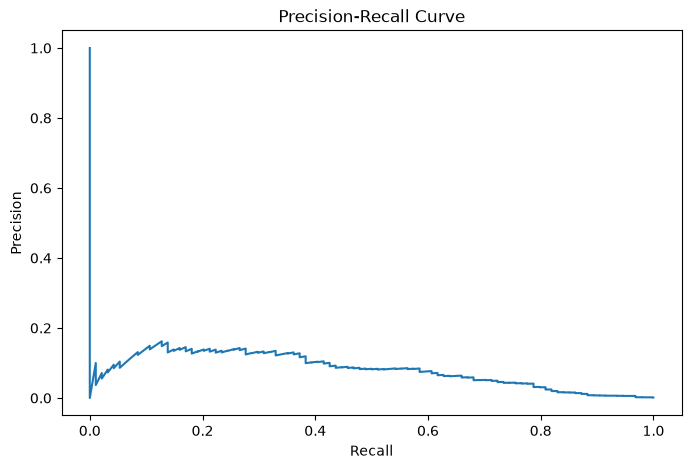

In [31]:
# Measure Average Precision
from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve
)

val_labels = y_val.to_numpy()

val_ap = average_precision_score(
    val_labels,
    val_scores
)

print("Validation Average Precision:", round(val_ap, 5))

precision, recall, thresholds = precision_recall_curve(
    val_labels,
    val_scores
)

plt.figure(figsize=(8, 5))
plt.plot(recall, precision)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.show()

In [32]:
#Choose a threshold using validation data
f1_values = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-12)
)

best_idx = int(np.argmax(f1_values))
threshold = float(thresholds[best_idx])

print("Selected threshold:", threshold)
print("Validation F1:", round(f1_values[best_idx], 5))

Selected threshold: 0.6130003781451572
Validation F1: 0.19155


Test Average Precision: 0.11215
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56651
       Fraud       0.14      0.39      0.21        95

    accuracy                           1.00     56746
   macro avg       0.57      0.69      0.60     56746
weighted avg       1.00      1.00      1.00     56746



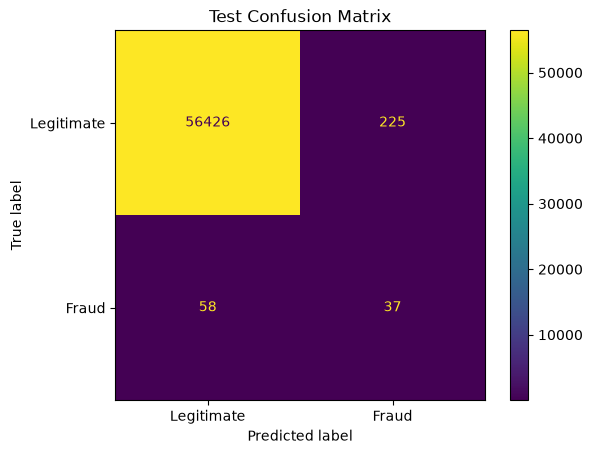

In [33]:
# TEST THE FINAL MODEL ON THE TEST SET
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

test_scores = -isolation_forest.score_samples(X_test_scaled)

test_predictions = (
    test_scores >= threshold
).astype(int)

print(
    "Test Average Precision:",
    round(average_precision_score(y_test, test_scores), 5)
)

print(
    classification_report(
        y_test,
        test_predictions,
        target_names=["Legitimate", "Fraud"],
        zero_division=0
    )
)

cm = confusion_matrix(y_test, test_predictions)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Legitimate", "Fraud"]
).plot(values_format="d")

plt.title("Test Confusion Matrix")
plt.show()

# SAVING THE TRAINED MODEL

In [34]:
import joblib

MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(exist_ok=True)

bundle = {
    "model": isolation_forest,
    "scaler": scaler,
    "threshold": threshold,
    "features": FEATURES,
    "model_name": "IsolationForest",
    "validation_average_precision": float(val_ap),
    "test_average_precision": float(
        average_precision_score(y_test, test_scores)
    ),
    "threshold_method": "Maximum validation F1"
}

model_path = MODEL_DIR / "fraud_detection_bundle.joblib"

joblib.dump(bundle, model_path)

print("Saved model to:", model_path)
print("File exists:", model_path.exists())

Saved model to: c:\Users\DELL\Downloads\Credit Card Fraud Detection\models\fraud_detection_bundle.joblib
File exists: True
